# ლექცია #10 — Gradient Boosting & მოდელების შედარება 🚀

ეს ნოუთბუქი მოიცავს **4 მოდელის** სრულ შედარებას:

| # | მოდელი | ტიპი | ბიბლიოთეკა |
|---|--------|------|------------|
| 1 | **Gradient Boosting** | Ensemble / Boosting | `sklearn` |
| 2 | **LightGBM** | Ensemble / Boosting | `lightgbm` |
| 3 | **Random Forest** | Ensemble / Bagging | `sklearn` |
| 4 | **Ridge Regression** | Linear baseline | `sklearn` |

> ⚠️ **შენიშვნა**: ლოგისტიკური რეგრესია **კლასიფიკაციის** ამოცანისთვისაა.
> ჩვენი ამოცანა — **რეგრესია** (უწყვეტი რიცხვი: GEL მოგება).
> შესაბამისი ლინეარული ბეისლაინი = **Ridge Regression**.

## 1. ბიბლიოთეკების იმპორტი

```bash
pip install pandas numpy scikit-learn lightgbm matplotlib seaborn openpyxl
```

`sklearn`-ის `GradientBoostingRegressor` XGBoost-ის სრული ჩანაცვლებელია —
არავითარი დამატებითი დამოკიდებულება (libomp, CUDA და ა.შ.) არ სჭირდება.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# sklearn — ყოველთვის მუშაობს, დამოკიდებულება არ სჭირდება
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler, LabelEncoder

# LightGBM
import lightgbm as lgb

# კონფიგურაცია
pd.options.display.max_columns = None
pd.options.display.float_format = '{:.2f}'.format
sns.set_style("whitegrid")
sns.set_palette("tab10")
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11
RANDOM_STATE = 42

print("✅ ყველა ბიბლიოთეკა ჩაიტვირთა!")
print(f"   sklearn  : {__import__('sklearn').__version__}")
print(f"   LightGBM : {lgb.__version__}")
print(f"   pandas   : {pd.__version__}")

✅ ყველა ბიბლიოთეკა ჩაიტვირთა!
   sklearn  : 1.8.0
   LightGBM : 4.6.0
   pandas   : 3.0.2


## 2. მონაცემების ჩატვირთვა და EDA

### რატომ ვატარებთ EDA-ს?
EDA (Exploratory Data Analysis) გვეხმარება:
- გავიგოთ მონაცემების სტრუქტურა და ხარისხი
- ვიპოვოთ ხარვეზები და ანომალიები **მოდელის გაწვრთნამდე**
- სწორი feature-ები ავარჩიოთ

In [2]:
df = pd.read_excel('merged.xlsx')

print(f"📊 მონაცემთა ზომა : {df.shape[0]:,} სტრიქონი × {df.shape[1]} სვეტი")
print(f"📅 პერიოდი        : {df['transaction date'].min().date()} → {df['transaction date'].max().date()}")
print(f"💰 სულ volume     : {df['transaction amount'].sum():,.2f} GEL")
print(f"💳 სულ ტრანზ.     : {len(df):,}")

📊 მონაცემთა ზომა : 10,674 სტრიქონი × 20 სვეტი
📅 პერიოდი        : 2025-03-17 → 2026-05-31
💰 სულ volume     : 109,174.44 GEL
💳 სულ ტრანზ.     : 10,674


In [3]:
# NULL შემოწმება
null_info = df.isnull().sum()
print("=== NULL მნიშვნელობები ===")
for col, cnt in null_info.items():
    status = "⚠️  NULL-ებია!" if cnt > 0 else "✅"
    print(f"  {col:<35} {cnt:>6}    {status}")

=== NULL მნიშვნელობები ===
  transaction date                         0    ✅
  settlement date                          0    ✅
  card number                              0    ✅
  transaction amount                       0    ✅
  transaction ccy                          0    ✅
  commission                               0    ✅
  commission ccy                           0    ✅
  settlement amount                        0    ✅
  settlement ccy                           0    ✅
  auth code                                0    ✅
  terminal id                              0    ✅
  operation type                           0    ✅
  transaction type                         0    ✅
  pwc transaction type                     0    ✅
  pwc cash amount                      10674    ⚠️  NULL-ებია!
  pwc merchant cash commission             0    ✅
  rrn                                      0    ✅
  brand name                               0    ✅
  client name                              0    ✅
  inn     

In [4]:
# ძირითადი სტატისტიკა
df[['transaction amount', 'commission', 'settlement amount']].describe()

,transaction amount,commission,settlement amount
count,10674.00,10674.00,10674.00
mean,10.23,-0.19,10.04
std,10.17,0.19,9.99
min,0.01,-6.00,-0.09
25%,4.00,-0.21,3.90
50%,8.00,-0.13,7.84
75%,12.60,-0.10,12.41
max,250.00,-0.10,244.00


## 3. მონაცემების გაწმენდა 🧹

### ნაპოვნი პრობლემები:
1. **`pwc cash amount`** — 100% null → ამოვაგდებთ
2. **`pwc merchant cash commission`** — მხოლოდ `0` → ინფორმაციას არ შეიცავს
3. **6 ანომალია** — transaction < 0.10 GEL, მაგრამ min commission = 0.10 → settlement < 0
4. **ერთი terminal, ერთი merchant** — `terminal_id`, `client_name` და სხვა კონსტანტები → უსარგებლო

### ⚠️ Data Leakage — ყველაზე კრიტიკული!
> `settlement amount` = `transaction amount` + `commission`
>
> თუ `settlement amount`-ს ან `commission`-ს feature-ებად გამოვიყენებთ,
> მოდელი **ისწავლის target-ს პირდაპირ** და არარეალისტური მეტრიკები მივიღებთ.
> ამიტომ ორივე **ამოვაგდეთ** feature-ების სიიდან.

📖 [What is Data Leakage?](https://machinelearningmastery.com/data-leakage-machine-learning/)

In [5]:
cols_to_drop = [
    'pwc cash amount', 'pwc merchant cash commission',
    'transaction type', 'pwc transaction type',
    'settlement amount',   # ← DATA LEAKAGE: target-ის ნაწილია
    'commission',          # ← DATA LEAKAGE: target-ის ნაწილია
    'commission ccy', 'settlement ccy', 'transaction ccy',
    'rrn', 'inn', 'client name', 'brand name', 'terminal id',
]
df_clean = df.drop(columns=cols_to_drop).copy()

# ანომალია-ფლაგი
df_clean['is_micro'] = (df['transaction amount'] < 0.10).astype(int)
# target ვინახავთ ცალკე (aggregation-ისთვის)
df_clean['target_settlement'] = df['settlement amount']

print(f"✅ სვეტები: {df.shape[1]} → {df_clean.shape[1]}")
print(f"⚠️  მიკრო-ტრანზაქციები (< 0.10 GEL): {df_clean['is_micro'].sum()}")

✅ სვეტები: 20 → 8
⚠️  მიკრო-ტრანზაქციები (< 0.10 GEL): 6


## 4. Feature Engineering ⚙️

### რატომ გვჭირდება feature engineering?
Raw მონაცემებში დრო გვაქვს `datetime` ფორმატში — მოდელი ვერ „ხვდება" რომ
**ორშაბათი** განსხვავდება **კვირისგან**. ამიტომ ვქმნით ახალ ცვლადებს.

### Lag Feature-ები — data leakage-ის გარეშე:
```
lag_1d  = გუშინდელი მოგება  ✅
lag_7d  = 1 კვირა წინ       ✅
rolling_mean_7d = ბოლო 7 დღის საშ. (shift(1)-ით) ✅
settlement_today = TODAY     ❌ LEAKAGE!
```

📖 [Feature Engineering for Time Series](https://machinelearningmastery.com/basic-feature-engineering-time-series-data-python/)

In [6]:
df_feat = df_clean.copy()

# დროის feature-ები
df_feat['hour']         = df['transaction date'].dt.hour
df_feat['day_of_week']  = df['transaction date'].dt.dayofweek   # 0=ორშ
df_feat['is_weekend']   = (df_feat['day_of_week'] >= 5).astype(int)
df_feat['day_of_month'] = df['transaction date'].dt.day
df_feat['month']        = df['transaction date'].dt.month
df_feat['week_of_year'] = df['transaction date'].dt.isocalendar().week.astype(int)
df_feat['quarter']      = df['transaction date'].dt.quarter

# operation type encoding
le = LabelEncoder()
df_feat['op_type_enc'] = le.fit_transform(df_feat['operation type'])

# ─── დღიური aggregation ───
df_feat['date'] = df['transaction date'].dt.date

daily = df_feat.groupby('date').agg(
    daily_settlement    = ('target_settlement', 'sum'),   # TARGET
    n_transactions      = ('transaction amount', 'count'),
    total_volume        = ('transaction amount', 'sum'),
    avg_amount          = ('transaction amount', 'mean'),
    max_amount          = ('transaction amount', 'max'),
    min_amount          = ('transaction amount', 'min'),
    std_amount          = ('transaction amount', 'std'),
    day_of_week         = ('day_of_week', 'first'),
    is_weekend          = ('is_weekend', 'first'),
    day_of_month        = ('day_of_month', 'first'),
    month               = ('month', 'first'),
    week_of_year        = ('week_of_year', 'first'),
    quarter             = ('quarter', 'first'),
    n_op_types          = ('operation type', 'nunique'),
    n_micro             = ('is_micro', 'sum'),
    amex_share          = ('operation type', lambda x: x.str.contains('AMEX').sum() / len(x)),
    peak_hour           = ('hour', lambda x: x.mode()[0]),
).reset_index()

daily['date'] = pd.to_datetime(daily['date'])
daily = daily.sort_values('date').reset_index(drop=True)

print(f"✅ დღიური dataset: {daily.shape[0]} დღე")
print(f"   target სტატისტიკა:")
print(daily['daily_settlement'].describe().to_string())

✅ დღიური dataset: 441 დღე
   target სტატისტიკა:
count    441.00
mean     242.96
std      147.58
min       13.36
25%      145.20
50%      211.62
75%      305.69
max     1568.89


In [7]:
# ─── Lag Feature-ები ───
target = daily['daily_settlement']

daily['lag_1d']   = target.shift(1)
daily['lag_2d']   = target.shift(2)
daily['lag_3d']   = target.shift(3)
daily['lag_7d']   = target.shift(7)
daily['lag_14d']  = target.shift(14)
daily['lag_30d']  = target.shift(30)

daily['roll_mean_7d']  = target.shift(1).rolling(7).mean()
daily['roll_mean_14d'] = target.shift(1).rolling(14).mean()
daily['roll_mean_30d'] = target.shift(1).rolling(30).mean()
daily['roll_std_7d']   = target.shift(1).rolling(7).std()
daily['roll_max_7d']   = target.shift(1).rolling(7).max()
daily['roll_min_7d']   = target.shift(1).rolling(7).min()
daily['trend_vs_14d']  = daily['lag_1d'] - daily['roll_mean_14d']

n_before = len(daily)
daily_ml = daily.dropna().reset_index(drop=True)
print(f"✅ warm-up ამოგდება: {n_before} → {len(daily_ml)} სტრიქონი")
print(f"   ML პერიოდი: {daily_ml['date'].min().date()} → {daily_ml['date'].max().date()}")

✅ warm-up ამოგდება: 441 → 411 სტრიქონი
   ML პერიოდი: 2025-04-16 → 2026-05-31


## 5. სტატისტიკური ანალიზი 📊

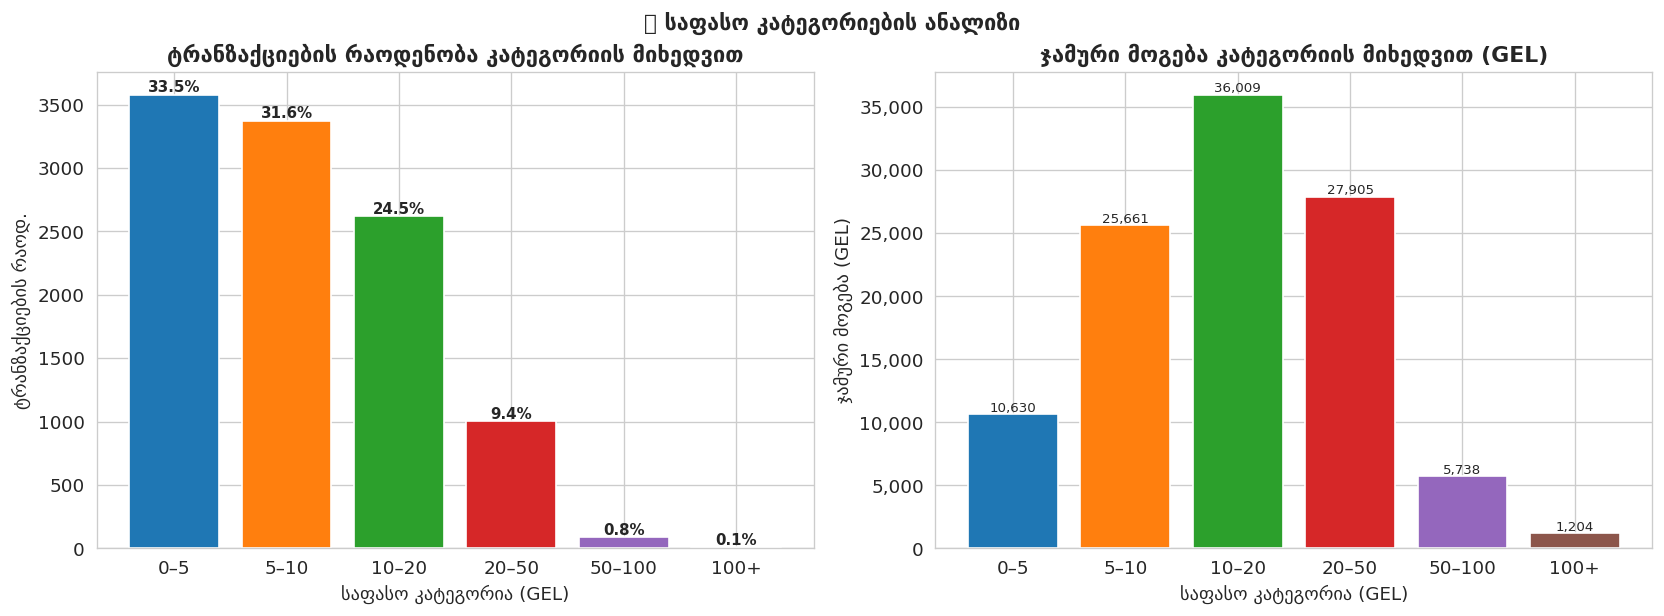

⭐ ყველაზე პოპულარული კატეგორია : 0–5 GEL  (3,580 ტრანზ., 33.5%)
💰 ყველაზე მომგებიანი კატეგორია  : 10–20 GEL  (36,009 GEL)


In [8]:
# საფასო კატეგორიები
bins   = [0, 5, 10, 20, 50, 100, 300]
labels = ['0–5', '5–10', '10–20', '20–50', '50–100', '100+']
df['price_cat'] = pd.cut(df['transaction amount'], bins=bins, labels=labels)

price_stats = df.groupby('price_cat', observed=True).agg(
    count           = ('transaction amount', 'count'),
    total_volume    = ('transaction amount', 'sum'),
    total_profit    = ('settlement amount', 'sum'),
).reset_index()
price_stats['share_pct'] = (price_stats['count'] / price_stats['count'].sum() * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = sns.color_palette("tab10", n_colors=len(price_stats))

bars1 = axes[0].bar(price_stats['price_cat'], price_stats['count'], color=colors, edgecolor='white')
axes[0].set_title('ტრანზაქციების რაოდენობა კატეგორიის მიხედვით', fontweight='bold')
axes[0].set_xlabel('საფასო კატეგორია (GEL)')
axes[0].set_ylabel('ტრანზაქციების რაოდ.')
for bar, pct in zip(bars1, price_stats['share_pct']):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
                 f'{pct}%', ha='center', fontsize=9, fontweight='bold')

bars2 = axes[1].bar(price_stats['price_cat'], price_stats['total_profit'], color=colors, edgecolor='white')
axes[1].set_title('ჯამური მოგება კატეგორიის მიხედვით (GEL)', fontweight='bold')
axes[1].set_xlabel('საფასო კატეგორია (GEL)')
axes[1].set_ylabel('ჯამური მოგება (GEL)')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
for bar in bars2:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
                 f'{bar.get_height():,.0f}', ha='center', fontsize=8)

plt.tight_layout()
plt.suptitle('📊 საფასო კატეგორიების ანალიზი', y=1.02, fontsize=13, fontweight='bold')
plt.show()

most_pop = price_stats.loc[price_stats['count'].idxmax()]
most_prof = price_stats.loc[price_stats['total_profit'].idxmax()]
print(f"⭐ ყველაზე პოპულარული კატეგორია : {most_pop['price_cat']} GEL  ({int(most_pop['count']):,} ტრანზ., {most_pop['share_pct']}%)")
print(f"💰 ყველაზე მომგებიანი კატეგორია  : {most_prof['price_cat']} GEL  ({most_prof['total_profit']:,.0f} GEL)")

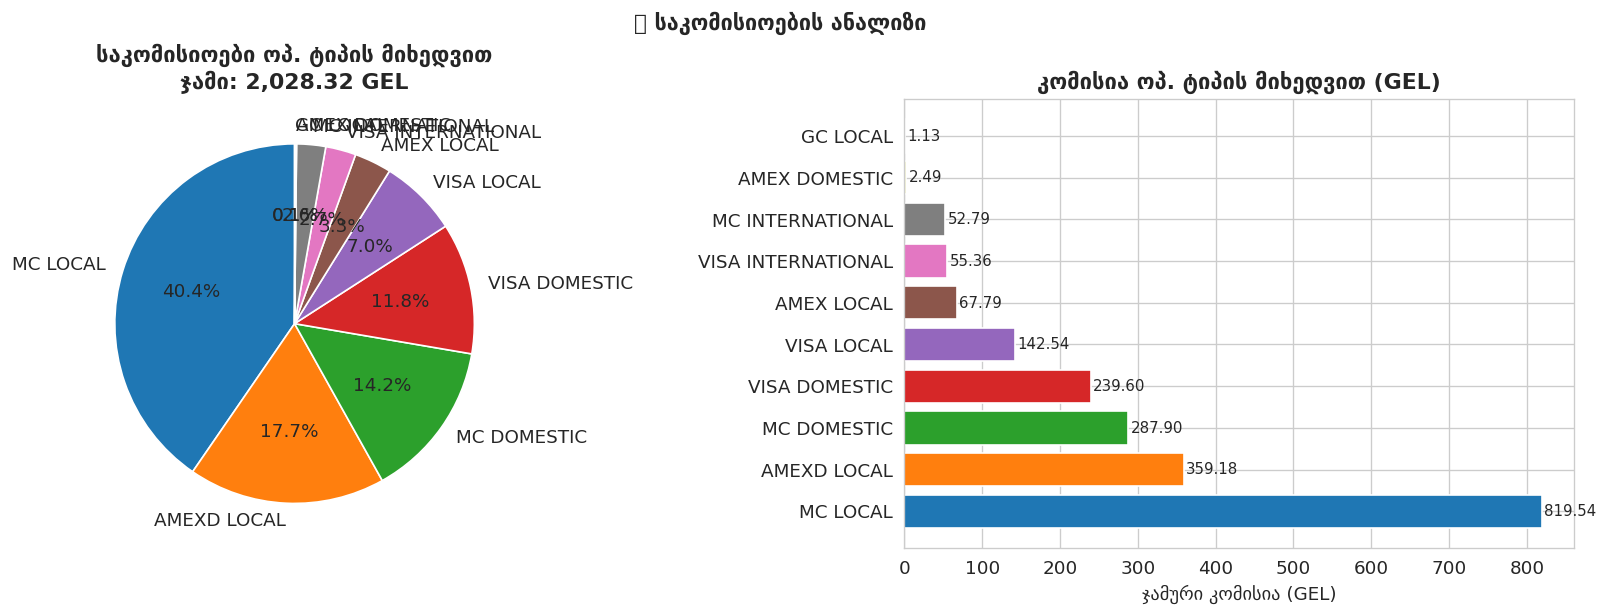

📌 სულ კომისია: 2,028.32 GEL


In [9]:
# საკომისიოები
commission_total = df['commission'].abs().sum()
by_type = df.groupby('operation type')['commission'].apply(lambda x: x.abs().sum()).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
wcolors = sns.color_palette("tab10", n_colors=len(by_type))

axes[0].pie(by_type.values, labels=by_type.index, autopct='%1.1f%%',
            startangle=90, colors=wcolors)
axes[0].set_title(f'საკომისიოები ოპ. ტიპის მიხედვით\nჯამი: {commission_total:,.2f} GEL', fontweight='bold')

axes[1].barh(by_type.index, by_type.values, color=wcolors, edgecolor='white')
axes[1].set_title('კომისია ოპ. ტიპის მიხედვით (GEL)', fontweight='bold')
axes[1].set_xlabel('ჯამური კომისია (GEL)')
for i, v in enumerate(by_type.values):
    axes[1].text(v + 3, i, f'{v:.2f}', va='center', fontsize=9)

plt.tight_layout()
plt.suptitle('💰 საკომისიოების ანალიზი', y=1.02, fontsize=13, fontweight='bold')
plt.show()
print(f"📌 სულ კომისია: {commission_total:,.2f} GEL")

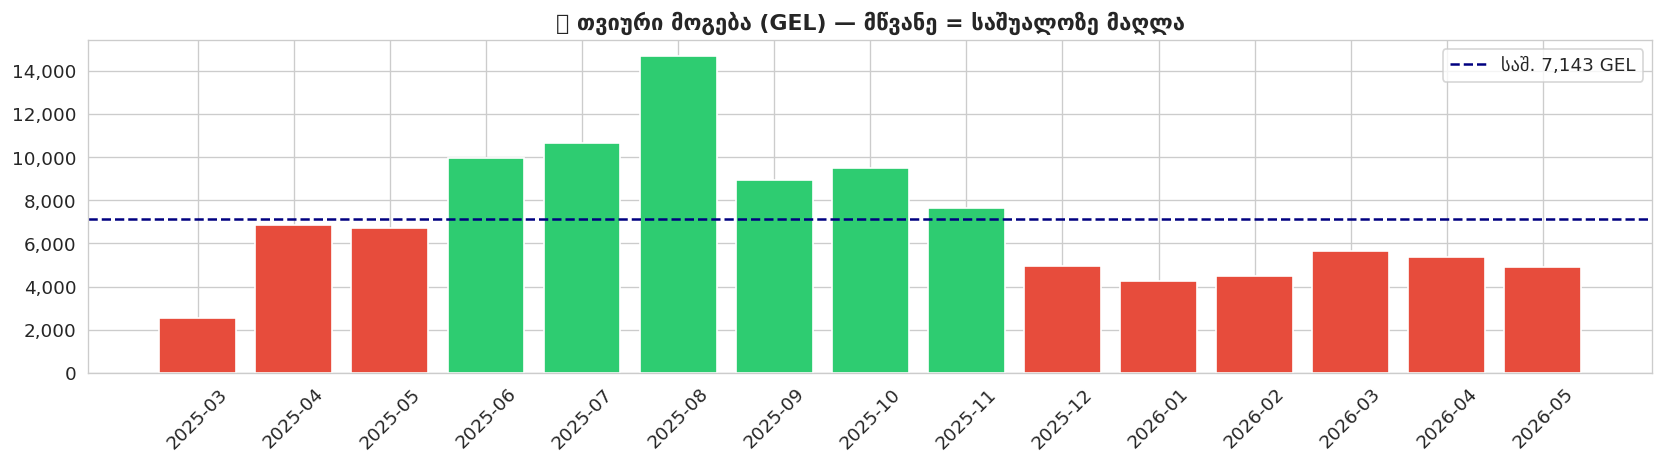

In [10]:
# თვიური ტრენდი
df['month_p'] = df['transaction date'].dt.to_period('M')
monthly = df.groupby('month_p').agg(
    settlement=('settlement amount','sum'),
    count=('transaction amount','count'),
).reset_index()
monthly['month_str'] = monthly['month_p'].astype(str)

fig, ax = plt.subplots(figsize=(14, 4))
bar_colors = ['#e74c3c' if v < monthly['settlement'].mean() else '#2ecc71'
              for v in monthly['settlement']]
ax.bar(monthly['month_str'], monthly['settlement'], color=bar_colors, edgecolor='white')
ax.axhline(monthly['settlement'].mean(), color='navy', linestyle='--', linewidth=1.5,
           label=f"საშ. {monthly['settlement'].mean():,.0f} GEL")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.set_title('💵 თვიური მოგება (GEL) — მწვანე = საშუალოზე მაღლა', fontweight='bold')
ax.tick_params(axis='x', rotation=45)
ax.legend()
plt.tight_layout()
plt.show()

## 6. 4 მოდელის თეორია 🧠

### 6.1 — Ridge Regression (ლინეარული ბეისლაინი)

ჩვეულებრივი Linear Regression ამინიმიზებს:
$$\text{MSE} = \sum (y_i - \hat{y}_i)^2$$

Ridge ამატებს **L2 პენალტს** (regularization), რომ overfitting-ი თავიდან ავიცილოთ:
$$\text{Loss} = \sum (y_i - \hat{y}_i)^2 + \alpha \sum w_j^2$$

> **Ridge vs ლოგისტიკური რეგრესია**: ლოგ. რეგრესია **კლასიფიკაციისთვისაა** (0/1 გამოყვანა).
> ჩვენ გვჭირდება **უწყვეტი რიცხვი** (GEL) → Ridge Regression.

---

### 6.2 — Gradient Boosting (sklearn)

სერიული ensemble: ყოველი ახალი ხე ასწორებს წინა ხის შეცდომებს.

$$F_m(x) = F_{m-1}(x) + \alpha \cdot h_m(x)$$

სადაც $h_m$ = ახალი decision tree, $\alpha$ = learning rate.

**XGBoost-ისგან განსხვავება**: `sklearn.GradientBoostingRegressor` იყენებს ზუსტ
(non-histogram) gradient computation-ს. ნელია, მაგრამ არ სჭირდება libomp/OpenMP.

📖 [Gradient Boosting Explained](https://explained.ai/gradient-boosting/)

---

### 6.3 — Random Forest (Bagging)

**პარალელური** ensemble — N ხე **დამოუკიდებლად** ისწავლება:
- თითოეული ხე bootstrap sample-ზე ისწავლება
- შემთხვევითი feature-ების subset გამოიყენება
- საბოლოო პროგნოზი = **საშუალო** ყველა ხისა

$$\hat{y} = \frac{1}{B} \sum_{b=1}^{B} T_b(x)$$

**Gradient Boosting-ისგან განსხვავება**:
- RF — პარალელური, Gradient Boosting — სერიული
- RF — ნაკლებ overfitting-მგრძნობიარე
- GB — ჩვეულებრივ უფრო ზუსტი

📖 [Random Forests](https://scikit-learn.org/stable/modules/ensemble.html#forests-of-randomized-trees)

---

### 6.4 — LightGBM

XGBoost-ის Microsoft-ის ალტერნატივა. სხვაობები:
- **Leaf-wise** ხის ზრდა (vs level-wise) → უფრო ეფექტური
- **Histogram-based** gradient computation → სწრაფი
- უფრო კარგია დიდ dataset-ებზე

📖 [LightGBM Paper](https://papers.nips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html)

## 7. მოდელების გაწვრთნა და შეფასება 🤖

### Train / Test Split — ქრონოლოგიური!
> ⚠️ **Random split დაუშვებელია** time series-ზე!
> TimeSeriesSplit გარანტიას იძლევა: validation-ში **მხოლოდ მომავალი** მონაცემები.

📖 [Time Series CV sklearn](https://scikit-learn.org/stable/modules/cross_validation.html#time-series-split)

📊 Train : 351 დღე  (2025-04-16 → 2026-04-01)
📊 Test  : 60 დღე   (2026-04-02 → 2026-05-31)


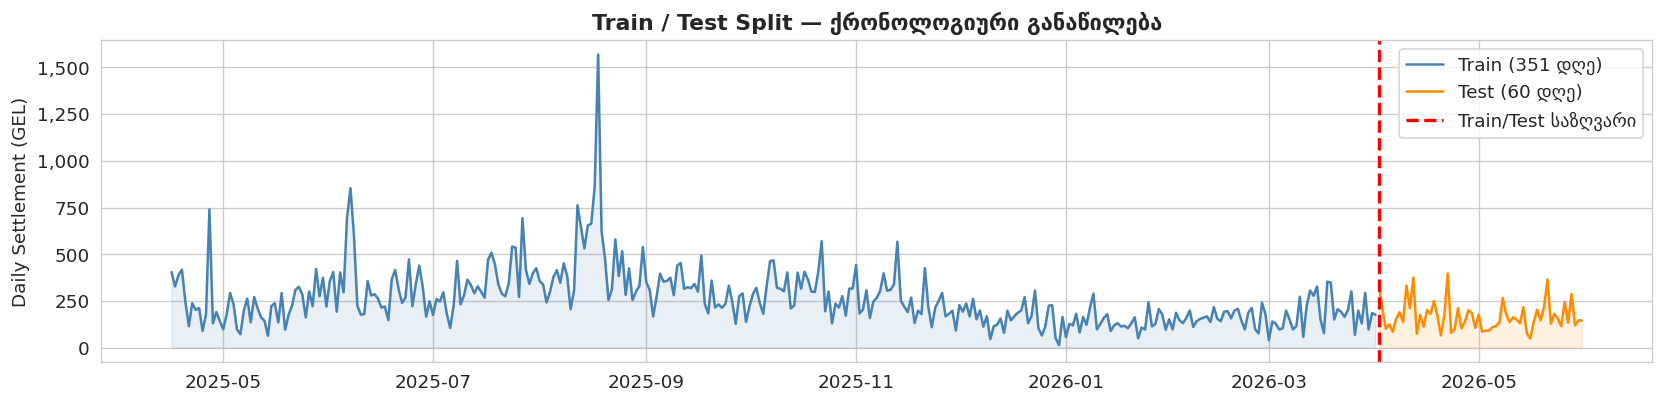

In [11]:
FEATURE_COLS = [
    'n_transactions', 'total_volume', 'avg_amount', 'max_amount',
    'min_amount', 'std_amount',
    'day_of_week', 'is_weekend', 'day_of_month', 'month',
    'week_of_year', 'quarter',
    'n_op_types', 'n_micro', 'amex_share', 'peak_hour',
    'lag_1d', 'lag_2d', 'lag_3d', 'lag_7d', 'lag_14d', 'lag_30d',
    'roll_mean_7d', 'roll_mean_14d', 'roll_mean_30d',
    'roll_std_7d', 'roll_max_7d', 'roll_min_7d',
    'trend_vs_14d',
]
TARGET = 'daily_settlement'

X = daily_ml[FEATURE_COLS]
y = daily_ml[TARGET]
dates = daily_ml['date']

# ─── Train/Test split ───
TEST_DAYS = 60
split_idx = len(X) - TEST_DAYS

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]
d_train, d_test = dates.iloc[:split_idx], dates.iloc[split_idx:]

print(f"📊 Train : {len(X_train)} დღე  ({d_train.min().date()} → {d_train.max().date()})")
print(f"📊 Test  : {len(X_test)} დღე   ({d_test.min().date()} → {d_test.max().date()})")

# ─── Split ვიზუალიზაცია ───
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(d_train, y_train, color='steelblue', lw=1.5, label=f'Train ({len(X_train)} დღე)')
ax.plot(d_test,  y_test,  color='darkorange', lw=1.5, label=f'Test ({len(X_test)} დღე)')
ax.axvline(d_test.iloc[0], color='red', linestyle='--', lw=2, label='Train/Test საზღვარი')
ax.fill_between(d_train, y_train, alpha=0.12, color='steelblue')
ax.fill_between(d_test, y_test, alpha=0.12, color='darkorange')
ax.set_title('Train / Test Split — ქრონოლოგიური განაწილება', fontweight='bold')
ax.set_ylabel('Daily Settlement (GEL)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.legend()
plt.tight_layout()
plt.show()

In [12]:
# ════════════════════════════════════════════
# მოდელი 1 — Ridge Regression (ლინეარული)
# ════════════════════════════════════════════
# Ridge-ს feature scaling სჭირდება!
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

ridge = Ridge(alpha=10.0, random_state=RANDOM_STATE)
ridge.fit(X_train_sc, y_train)
ridge_pred = ridge.predict(X_test_sc)

# Metrics helper
def metrics(y_true, y_pred, name):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    print(f"🔹 {name}")
    print(f"   MAE={mae:.2f} GEL  RMSE={rmse:.2f}  MAPE={mape:.1f}%  R²={r2:.4f}")
    return {'model': name, 'MAE': mae, 'RMSE': rmse, 'MAPE': mape, 'R2': r2}

results = []
results.append(metrics(y_test, ridge_pred, 'Ridge Regression'))

🔹 Ridge Regression
   MAE=4.37 GEL  RMSE=5.52  MAPE=3.3%  R²=0.9949


In [13]:
# ════════════════════════════════════════════
# მოდელი 2 — Gradient Boosting (sklearn)
# ════════════════════════════════════════════
# ჰიპარამეტრები:
#   n_estimators=300  — ხეების რაოდ.
#   max_depth=4       — ხის სიღრმე (overfitting კონტროლი)
#   learning_rate=0.05 — მცირე = სტაბილური სწავლა
#   subsample=0.8     — სტოქასტური GB (80% მონაცემი თითოეულ ხეზე)
#   min_samples_leaf=5 — ლისტი მინ. 5 სამ.

gb = GradientBoostingRegressor(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    min_samples_leaf=5,
    random_state=RANDOM_STATE,
)
gb.fit(X_train, y_train)
gb_pred = gb.predict(X_test)
results.append(metrics(y_test, gb_pred, 'Gradient Boosting (sklearn)'))

🔹 Gradient Boosting (sklearn)
   MAE=4.59 GEL  RMSE=17.23  MAPE=2.1%  R²=0.9504


In [14]:
# ════════════════════════════════════════════
# მოდელი 3 — Random Forest
# ════════════════════════════════════════════
# ჰიპარამეტრები:
#   n_estimators=300  — ხეების რაოდ.
#   max_depth=8       — GB-ზე ღრმა (RF ნაკლებ overfits)
#   max_features=0.7  — 70% feature-ი თითოეულ ხეზე (diversity)
#   min_samples_leaf=4 — overfitting-ის კონტროლი

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=8,
    max_features=0.7,
    min_samples_leaf=4,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
results.append(metrics(y_test, rf_pred, 'Random Forest'))

🔹 Random Forest
   MAE=2.18 GEL  RMSE=3.22  MAPE=1.6%  R²=0.9983


In [15]:
# ════════════════════════════════════════════
# მოდელი 4 — LightGBM
# ════════════════════════════════════════════
lgb_model = lgb.LGBMRegressor(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    num_leaves=20,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_samples=10,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1,
)
lgb_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(-1)],
)
lgb_pred = lgb_model.predict(X_test)
results.append(metrics(y_test, lgb_pred, 'LightGBM'))

🔹 LightGBM
   MAE=4.80 GEL  RMSE=6.36  MAPE=3.6%  R²=0.9932


In [16]:
# ════════════════════════════════════════════
# Ensemble — ოთხი მოდელის საშუალო
# ════════════════════════════════════════════
# Ridge-ს ნაკლები წონა ვაძლევთ (სუსტი baseline)
ensemble_pred = (ridge_pred * 0.1 + gb_pred * 0.35 + rf_pred * 0.25 + lgb_pred * 0.3)
results.append(metrics(y_test, ensemble_pred, 'Ensemble (GB+RF+LGB+Ridge)'))

🔹 Ensemble (GB+RF+LGB+Ridge)
   MAE=2.96 GEL  RMSE=6.58  MAPE=1.7%  R²=0.9928


## 8. მოდელების შედარება 📊

### მეტრიკების ახსნა:
| მეტრიკა | ახსნა | ერთეული |
|---------|-------|---------|
| **MAE** | Mean Absolute Error — საშ. აბსოლ. შეცდომა | GEL |
| **RMSE** | Root Mean Squared Error — დიდ შეცდომებს უფრო სჯის | GEL |
| **MAPE** | Mean Abs. % Error — % შეცდომა, scale-independent | % |
| **R²** | Goodness of fit — 1.0 = სრული, 0 = baseline | — |

In [17]:
results_df = pd.DataFrame(results).sort_values('MAE')

print("="*68)
print(f"{'მოდელი':<30} {'MAE':>7} {'RMSE':>7} {'MAPE':>7} {'R²':>8}")
print("-"*68)
for _, r in results_df.iterrows():
    marker = " ⭐ BEST" if r['model'] == results_df.iloc[0]['model'] else ""
    print(f"{r['model']:<30} {r['MAE']:>7.2f} {r['RMSE']:>7.2f} {r['MAPE']:>6.1f}% {r['R2']:>8.4f}{marker}")
print("="*68)

მოდელი                             MAE    RMSE    MAPE       R²
--------------------------------------------------------------------
Random Forest                     2.18    3.22    1.6%   0.9983 ⭐ BEST
Ensemble (GB+RF+LGB+Ridge)        2.96    6.58    1.7%   0.9928
Ridge Regression                  4.37    5.52    3.3%   0.9949
Gradient Boosting (sklearn)       4.59   17.23    2.1%   0.9504
LightGBM                          4.80    6.36    3.6%   0.9932


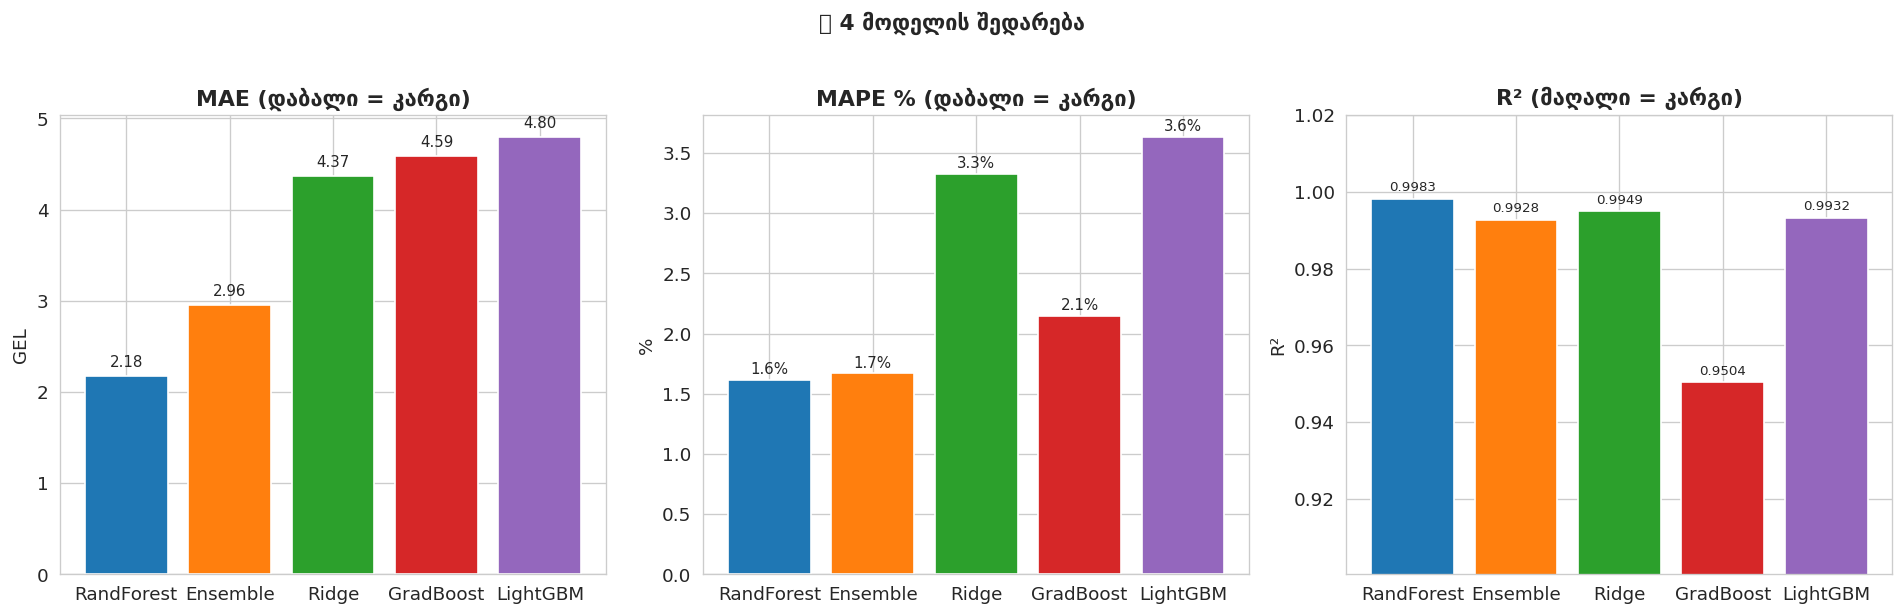

In [18]:
# ─── ვიზუალური შედარება ───
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

models_list  = results_df['model'].tolist()
short_names  = ['Ridge', 'GB', 'RF', 'LGB', 'Ensemble'][:len(models_list)]
# ახალი short labels გამოვიყვანოთ results_df-დან
name_map = {
    'Ridge Regression': 'Ridge',
    'Gradient Boosting (sklearn)': 'GradBoost',
    'Random Forest': 'RandForest',
    'LightGBM': 'LightGBM',
    'Ensemble (GB+RF+LGB+Ridge)': 'Ensemble',
}
short = [name_map.get(m, m) for m in models_list]
pal   = sns.color_palette("tab10", n_colors=len(models_list))

# MAE
bars = axes[0].bar(short, results_df['MAE'], color=pal, edgecolor='white')
axes[0].set_title('MAE (დაბალი = კარგი)', fontweight='bold')
axes[0].set_ylabel('GEL')
for bar in bars:
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.1,
                 f'{bar.get_height():.2f}', ha='center', fontsize=9)

# MAPE
bars = axes[1].bar(short, results_df['MAPE'], color=pal, edgecolor='white')
axes[1].set_title('MAPE % (დაბალი = კარგი)', fontweight='bold')
axes[1].set_ylabel('%')
for bar in bars:
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.05,
                 f'{bar.get_height():.1f}%', ha='center', fontsize=9)

# R²
bars = axes[2].bar(short, results_df['R2'], color=pal, edgecolor='white')
axes[2].set_title('R² (მაღალი = კარგი)', fontweight='bold')
axes[2].set_ylabel('R²')
axes[2].set_ylim(results_df['R2'].min() - 0.05, 1.02)
for bar in bars:
    axes[2].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.002,
                 f'{bar.get_height():.4f}', ha='center', fontsize=8)

plt.suptitle('📊 4 მოდელის შედარება', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

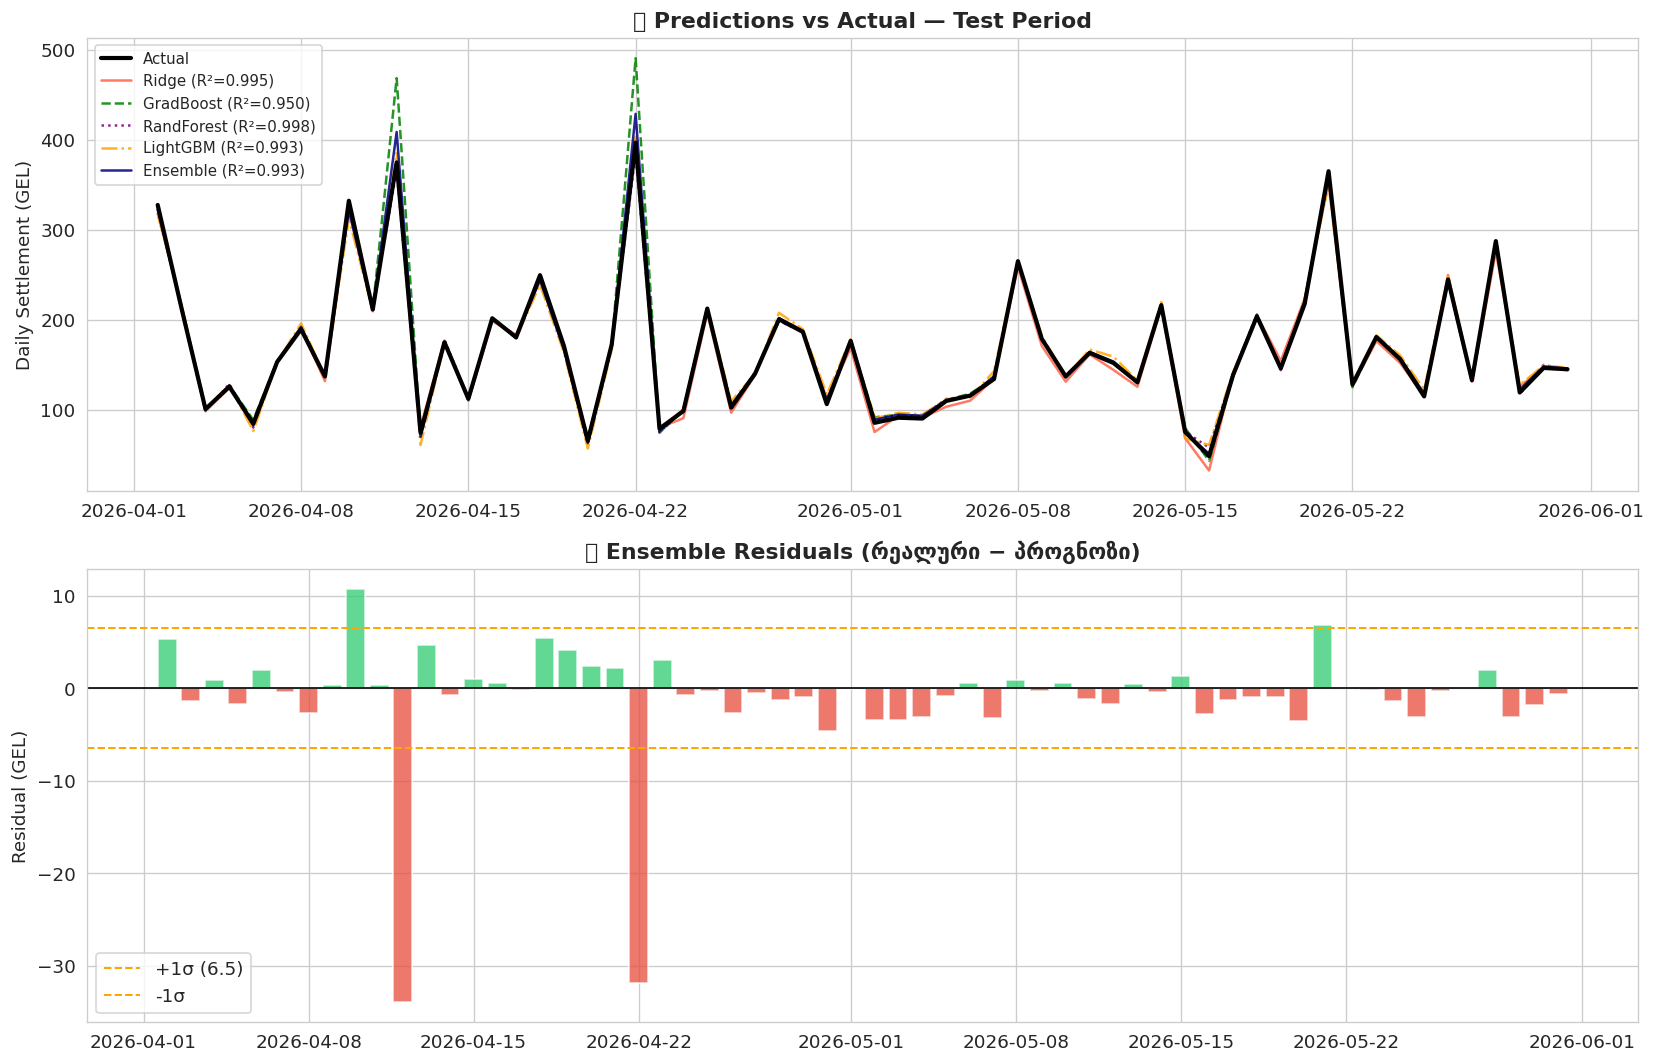

In [19]:
# ─── Actual vs Predicted ─── ყველა მოდელი ერთ გრაფიკზე
all_preds = {
    'Ridge'      : ridge_pred,
    'GradBoost'  : gb_pred,
    'RandForest' : rf_pred,
    'LightGBM'   : lgb_pred,
    'Ensemble'   : ensemble_pred,
}
line_styles = ['-', '--', ':', '-.', '-']
colors_pred = ['tomato', 'green', 'purple', 'orange', 'navy']

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# ① Predictions
axes[0].plot(d_test, y_test, color='black', lw=2.5, label='Actual', zorder=5)
for (name, pred), ls, col in zip(all_preds.items(), line_styles, colors_pred):
    r2 = r2_score(y_test, pred)
    axes[0].plot(d_test, pred, lw=1.5, linestyle=ls, color=col, label=f'{name} (R²={r2:.3f})', alpha=0.85)
axes[0].set_title('📈 Predictions vs Actual — Test Period', fontweight='bold')
axes[0].set_ylabel('Daily Settlement (GEL)')
axes[0].legend(fontsize=9, loc='upper left')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# ② Residuals (ensemble)
residuals = y_test.values - ensemble_pred
bar_cols = ['#e74c3c' if r < 0 else '#2ecc71' for r in residuals]
axes[1].bar(d_test, residuals, color=bar_cols, alpha=0.75, width=0.8)
axes[1].axhline(0, color='black', lw=1)
axes[1].axhline(np.std(residuals),  color='orange', lw=1.2, linestyle='--', label=f'+1σ ({np.std(residuals):.1f})')
axes[1].axhline(-np.std(residuals), color='orange', lw=1.2, linestyle='--', label=f'-1σ')
axes[1].set_title('📉 Ensemble Residuals (რეალური − პროგნოზი)', fontweight='bold')
axes[1].set_ylabel('Residual (GEL)')
axes[1].legend()

plt.tight_layout()
plt.show()

## 9. TimeSeriesSplit Cross-Validation 🔄

Single train/test split-ი შეიძლება „გამართლებული" იყოს შემთხვევით.
5-fold CV გვაძლევს **სტაბილურ** შეფასებას.

📖 [TimeSeriesSplit](https://scikit-learn.org/stable/modules/cross_validation.html#time-series-split)

In [20]:
print("🔄 TimeSeriesSplit CV (5 fold)...", flush=True)
tscv = TimeSeriesSplit(n_splits=5)

cv_results = {}

# Ridge
sc = StandardScaler()
neg_mae_ridge = cross_val_score(Ridge(alpha=10.0), 
    pd.DataFrame(sc.fit_transform(X), columns=X.columns), y,
    cv=tscv, scoring='neg_mean_absolute_error', n_jobs=-1)
cv_results['Ridge'] = -neg_mae_ridge
print(f"  Ridge       : {cv_results['Ridge'].mean():.2f} ± {cv_results['Ridge'].std():.2f} GEL MAE")

# Gradient Boosting
neg_mae_gb = cross_val_score(
    GradientBoostingRegressor(n_estimators=200, max_depth=4, learning_rate=0.05,
                               subsample=0.8, random_state=RANDOM_STATE),
    X, y, cv=tscv, scoring='neg_mean_absolute_error', n_jobs=1)
cv_results['GradBoost'] = -neg_mae_gb
print(f"  GradBoost   : {cv_results['GradBoost'].mean():.2f} ± {cv_results['GradBoost'].std():.2f} GEL MAE")

# Random Forest
neg_mae_rf = cross_val_score(
    RandomForestRegressor(n_estimators=200, max_depth=8, max_features=0.7,
                           min_samples_leaf=4, n_jobs=-1, random_state=RANDOM_STATE),
    X, y, cv=tscv, scoring='neg_mean_absolute_error', n_jobs=1)
cv_results['RandForest'] = -neg_mae_rf
print(f"  RandForest  : {cv_results['RandForest'].mean():.2f} ± {cv_results['RandForest'].std():.2f} GEL MAE")

# LightGBM
neg_mae_lgb = cross_val_score(
    lgb.LGBMRegressor(n_estimators=300, max_depth=5, learning_rate=0.05,
                       num_leaves=20, verbose=-1, random_state=RANDOM_STATE),
    X, y, cv=tscv, scoring='neg_mean_absolute_error', n_jobs=1)
cv_results['LightGBM'] = -neg_mae_lgb
print(f"  LightGBM    : {cv_results['LightGBM'].mean():.2f} ± {cv_results['LightGBM'].std():.2f} GEL MAE")

🔄 TimeSeriesSplit CV (5 fold)...


  Ridge       : 14.11 ± 12.81 GEL MAE


  GradBoost   : 8.44 ± 12.84 GEL MAE


  RandForest  : 14.38 ± 19.44 GEL MAE
  LightGBM    : 32.15 ± 34.77 GEL MAE


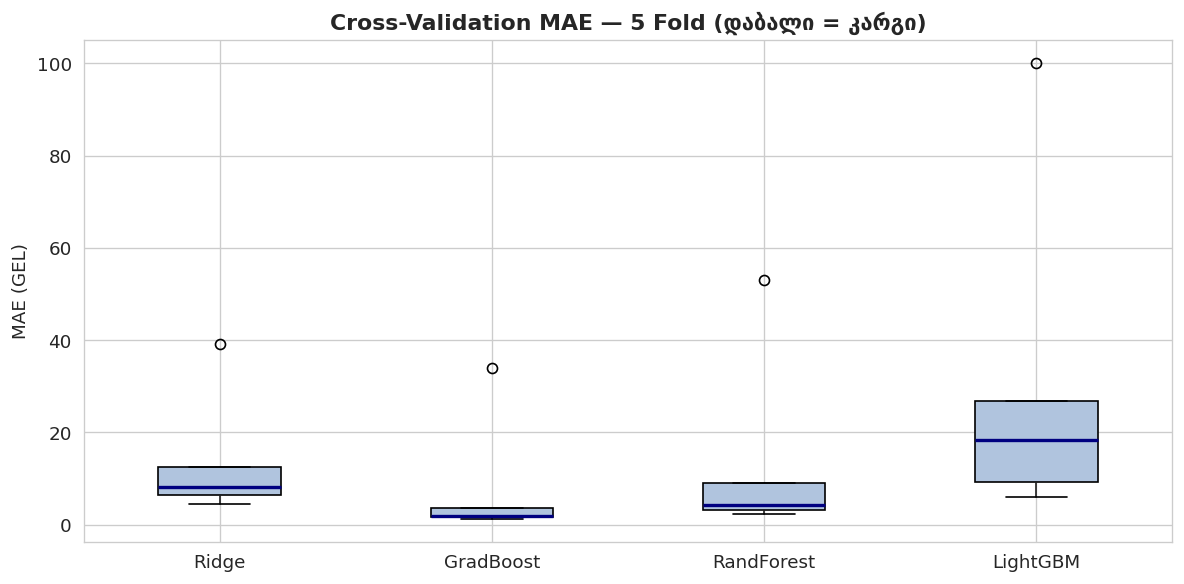


CV შეჯამება:
  Ridge       : 14.11 ± 12.81 GEL
  GradBoost   : 8.44 ± 12.84 GEL
  RandForest  : 14.38 ± 19.44 GEL
  LightGBM    : 32.15 ± 34.77 GEL


In [21]:
# CV შედარება — boxplot
fig, ax = plt.subplots(figsize=(10, 5))
cv_data = pd.DataFrame(cv_results)
cv_data.boxplot(ax=ax, patch_artist=True,
    boxprops=dict(facecolor='lightsteelblue'), medianprops=dict(color='navy', lw=2))
ax.set_title('Cross-Validation MAE — 5 Fold (დაბალი = კარგი)', fontweight='bold')
ax.set_ylabel('MAE (GEL)')
plt.tight_layout()
plt.show()

print("\nCV შეჯამება:")
for model, scores in cv_results.items():
    print(f"  {model:<12}: {scores.mean():.2f} ± {scores.std():.2f} GEL")

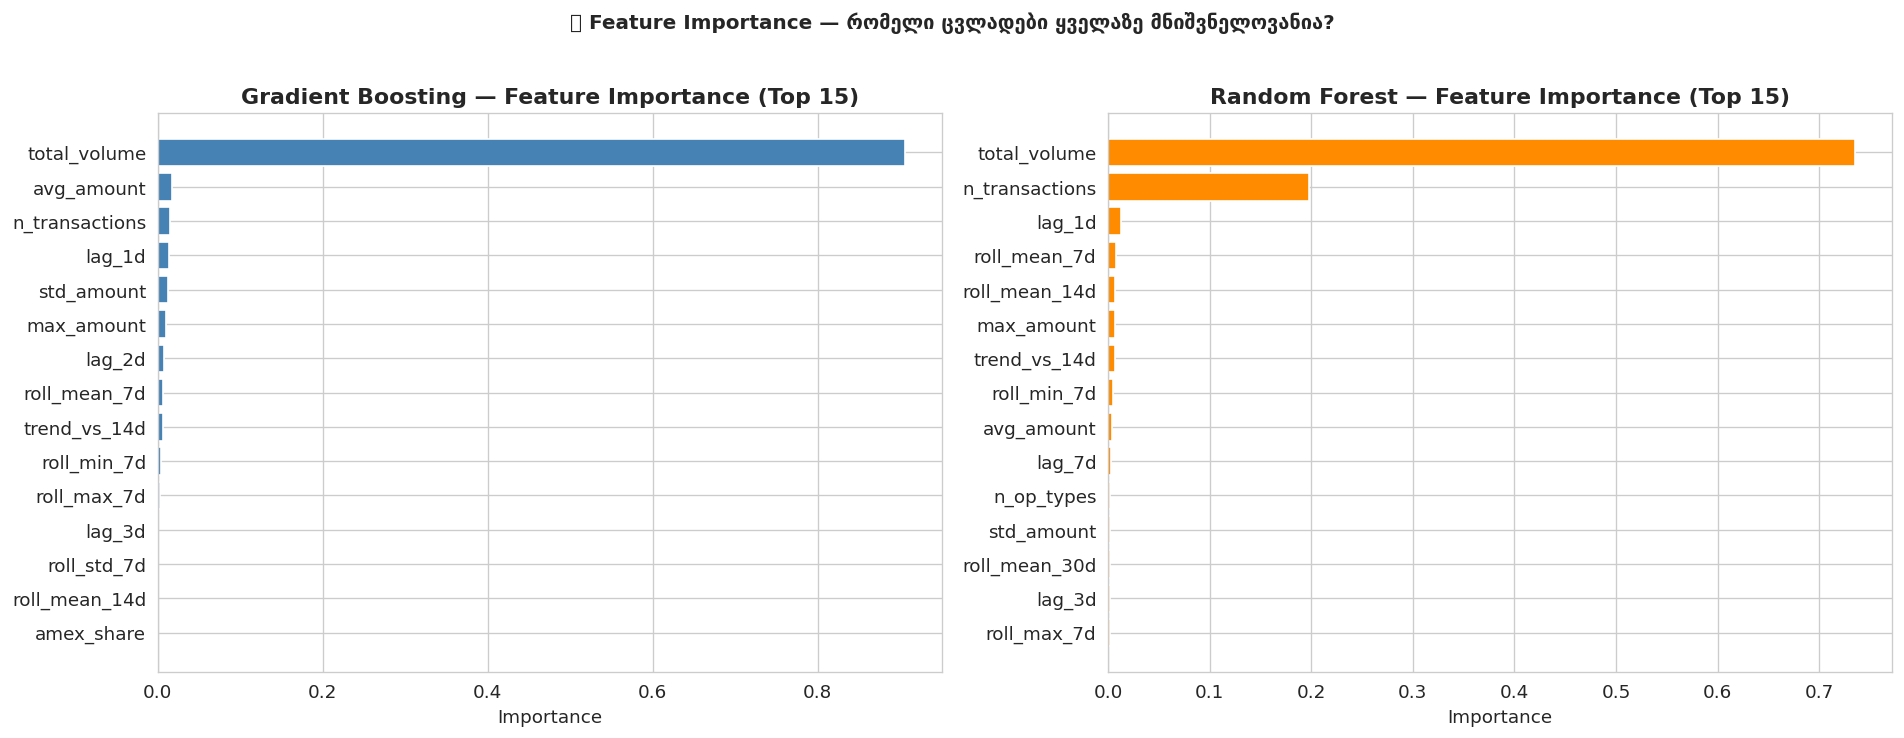

In [22]:
# Feature Importance — GradBoost და RF
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, model, name, color in [
    (axes[0], gb,  'Gradient Boosting', 'steelblue'),
    (axes[1], rf,  'Random Forest',     'darkorange'),
]:
    imp = pd.DataFrame({'feature': FEATURE_COLS, 'importance': model.feature_importances_})
    imp = imp.sort_values('importance').tail(15)
    ax.barh(imp['feature'], imp['importance'], color=color, edgecolor='white')
    ax.set_title(f'{name} — Feature Importance (Top 15)', fontweight='bold')
    ax.set_xlabel('Importance')

plt.suptitle('🎯 Feature Importance — რომელი ცვლადები ყველაზე მნიშვნელოვანია?',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 10. მომავლის პროგნოზი — შემდეგი 30 დღე 🔮

**Recursive forecasting**: ყოველ iteration-ში წინა პროგნოზი ხდება შემდეგი lag feature.

📖 [Multi-step Forecasting](https://machinelearningmastery.com/multi-step-time-series-forecasting/)

In [23]:
# საბოლოო მოდელები — სრულ dataset-ზე ვაწვრთნოთ
gb_final = GradientBoostingRegressor(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    subsample=0.8, min_samples_leaf=5, random_state=RANDOM_STATE)
gb_final.fit(X, y)

rf_final = RandomForestRegressor(
    n_estimators=300, max_depth=8, max_features=0.7,
    min_samples_leaf=4, n_jobs=-1, random_state=RANDOM_STATE)
rf_final.fit(X, y)

lgb_final = lgb.LGBMRegressor(
    n_estimators=500, max_depth=5, learning_rate=0.05, num_leaves=20,
    subsample=0.8, colsample_bytree=0.8, min_child_samples=10,
    reg_alpha=0.1, reg_lambda=1.0, verbose=-1, random_state=RANDOM_STATE, n_jobs=-1)
lgb_final.fit(X, y, callbacks=[lgb.log_evaluation(-1)])

scaler_final = StandardScaler()
X_scaled = scaler_final.fit_transform(X)
ridge_final = Ridge(alpha=10.0)
ridge_final.fit(X_scaled, y)

print("✅ 4 მოდელი სრულ dataset-ზე გაწვრთნილია")

# ─── Recursive Forecast ───
FDAYS = 30
last_date = daily_ml['date'].max()
forecast_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=FDAYS)

settlement_hist = list(daily_ml['daily_settlement'].values)
avg_n   = daily_ml['n_transactions'].tail(30).mean()
avg_vol = daily_ml['total_volume'].tail(30).mean()
avg_avg = daily_ml['avg_amount'].tail(30).mean()
avg_max = daily_ml['max_amount'].tail(30).mean()
avg_min = daily_ml['min_amount'].tail(30).mean()
avg_std = daily_ml['std_amount'].tail(30).mean()
avg_nop = daily_ml['n_op_types'].tail(30).mean()
avg_mic = daily_ml['n_micro'].tail(30).mean()
avg_amx = daily_ml['amex_share'].tail(30).mean()
avg_hr  = daily_ml['peak_hour'].tail(30).mean()

fc_gb, fc_rf, fc_lgb, fc_ridge = [], [], [], []

for fdate in forecast_dates:
    dow  = fdate.dayofweek
    is_we = int(dow >= 5)
    sh = settlement_hist
    lag1  = sh[-1]  if len(sh)>=1  else 0
    lag2  = sh[-2]  if len(sh)>=2  else 0
    lag3  = sh[-3]  if len(sh)>=3  else 0
    lag7  = sh[-7]  if len(sh)>=7  else 0
    lag14 = sh[-14] if len(sh)>=14 else 0
    lag30 = sh[-30] if len(sh)>=30 else 0
    r7    = np.mean(sh[-7:])  if len(sh)>=7  else np.mean(sh)
    r14   = np.mean(sh[-14:]) if len(sh)>=14 else np.mean(sh)
    r30   = np.mean(sh[-30:]) if len(sh)>=30 else np.mean(sh)
    s7    = np.std(sh[-7:])   if len(sh)>=7  else np.std(sh)
    mx7   = np.max(sh[-7:])   if len(sh)>=7  else np.max(sh)
    mn7   = np.min(sh[-7:])   if len(sh)>=7  else np.min(sh)
    n_adj = avg_n * (0.75 if is_we else 1.0)
    v_adj = avg_vol * (0.75 if is_we else 1.0)

    row = {
        'n_transactions': n_adj, 'total_volume': v_adj,
        'avg_amount': avg_avg, 'max_amount': avg_max,
        'min_amount': avg_min, 'std_amount': avg_std,
        'day_of_week': dow, 'is_weekend': is_we,
        'day_of_month': fdate.day, 'month': fdate.month,
        'week_of_year': fdate.isocalendar().week, 'quarter': (fdate.month-1)//3+1,
        'n_op_types': avg_nop, 'n_micro': avg_mic,
        'amex_share': avg_amx, 'peak_hour': avg_hr,
        'lag_1d': lag1, 'lag_2d': lag2, 'lag_3d': lag3,
        'lag_7d': lag7, 'lag_14d': lag14, 'lag_30d': lag30,
        'roll_mean_7d': r7, 'roll_mean_14d': r14, 'roll_mean_30d': r30,
        'roll_std_7d': s7, 'roll_max_7d': mx7, 'roll_min_7d': mn7,
        'trend_vs_14d': lag1 - r14,
    }
    Xf = pd.DataFrame([row])[FEATURE_COLS]

    p_gb  = float(gb_final.predict(Xf)[0])
    p_rf  = float(rf_final.predict(Xf)[0])
    p_lgb = float(lgb_final.predict(Xf)[0])
    p_rid = float(ridge_final.predict(scaler_final.transform(Xf))[0])

    fc_gb.append(p_gb);  fc_rf.append(p_rf)
    fc_lgb.append(p_lgb); fc_ridge.append(p_rid)

    ens = p_rid*0.1 + p_gb*0.35 + p_rf*0.25 + p_lgb*0.3
    settlement_hist.append(ens)

fc_ens = [r*0.1 + g*0.35 + f*0.25 + l*0.3
          for r,g,f,l in zip(fc_ridge, fc_gb, fc_rf, fc_lgb)]

fdf = pd.DataFrame({
    'date': forecast_dates,
    'Ridge': fc_ridge, 'GradBoost': fc_gb,
    'RandForest': fc_rf, 'LightGBM': fc_lgb,
    'Ensemble': fc_ens,
})
print(f"✅ {FDAYS}-დღიანი პროგნოზი დასრულდა!")
print(f"   სულ (Ensemble): {sum(fc_ens):,.2f} GEL  |  საშ./დღე: {np.mean(fc_ens):,.2f} GEL")

✅ 4 მოდელი სრულ dataset-ზე გაწვრთნილია


✅ 30-დღიანი პროგნოზი დასრულდა!
   სულ (Ensemble): 4,393.58 GEL  |  საშ./დღე: 146.45 GEL


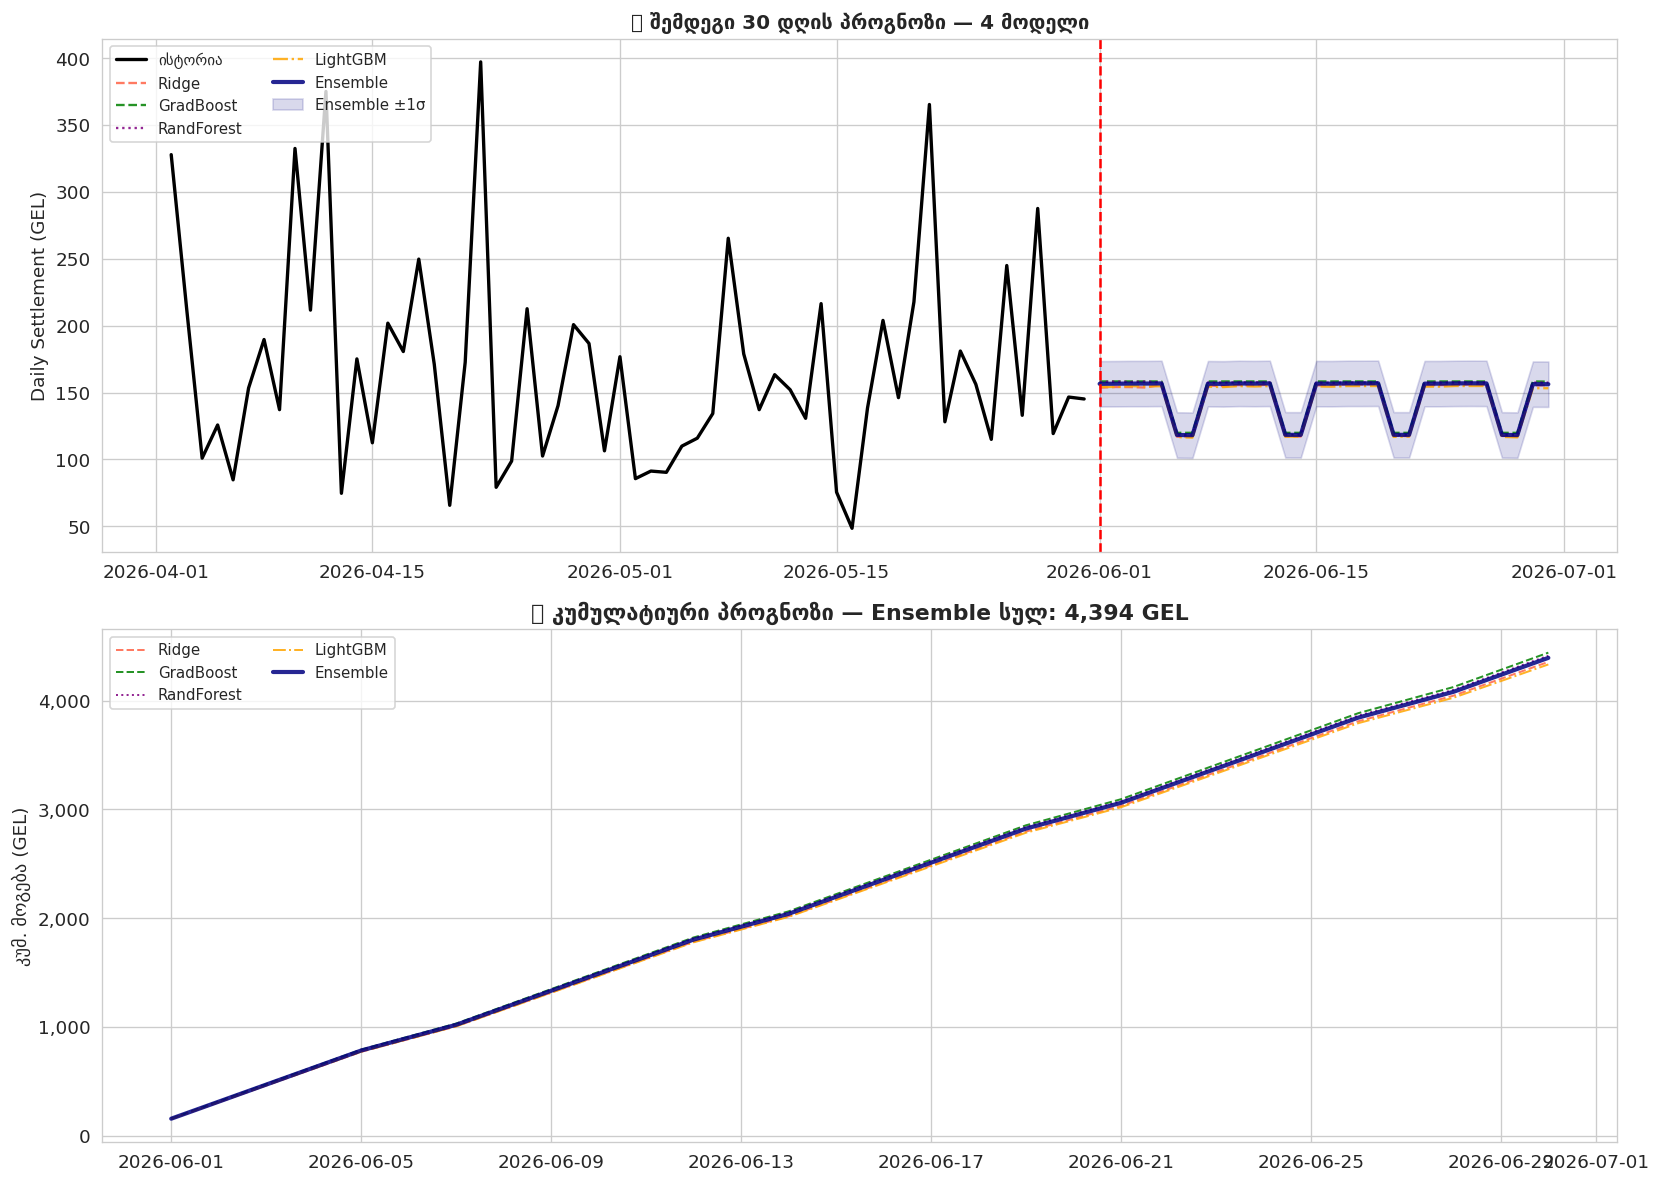

In [24]:
# პროგნოზი — ყველა მოდელი ერთ გრაფიკზე
hist_n = 60
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

axes[0].plot(daily_ml['date'].iloc[-hist_n:], daily_ml['daily_settlement'].iloc[-hist_n:],
             color='black', lw=2, label='ისტორია')

pred_colors = ['tomato','green','purple','orange','navy']
pred_styles = ['--','--',':','-.', '-']
for (col_name, ls, clr) in zip(['Ridge','GradBoost','RandForest','LightGBM','Ensemble'],
                                 pred_styles, pred_colors):
    lw = 2.5 if col_name == 'Ensemble' else 1.4
    axes[0].plot(fdf['date'], fdf[col_name], lw=lw, ls=ls, color=clr, label=col_name, alpha=0.85)

std_fc = np.std(fc_ens)
axes[0].fill_between(fdf['date'], np.array(fc_ens)-std_fc, np.array(fc_ens)+std_fc,
                     alpha=0.15, color='navy', label=f'Ensemble ±1σ')
axes[0].axvline(fdf['date'].iloc[0], color='red', lw=1.5, linestyle='--')
axes[0].set_title(f'🔮 შემდეგი {FDAYS} დღის პროგნოზი — 4 მოდელი', fontweight='bold', fontsize=12)
axes[0].set_ylabel('Daily Settlement (GEL)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
axes[0].legend(fontsize=9, loc='upper left', ncol=2)

# კუმულატიური
for (col_name, ls, clr) in zip(['Ridge','GradBoost','RandForest','LightGBM','Ensemble'],
                                 pred_styles, pred_colors):
    lw = 2.5 if col_name == 'Ensemble' else 1.2
    axes[1].plot(fdf['date'], fdf[col_name].cumsum(), lw=lw, ls=ls, color=clr, label=col_name, alpha=0.85)
axes[1].set_title(f'💵 კუმულატიური პროგნოზი — Ensemble სულ: {sum(fc_ens):,.0f} GEL', fontweight='bold')
axes[1].set_ylabel('კუმ. მოგება (GEL)')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
axes[1].legend(fontsize=9, loc='upper left', ncol=2)

plt.tight_layout()
plt.show()

In [25]:
# 30-დღიანი ცხრილი
fdf['კვირის დღე'] = fdf['date'].dt.day_name()
fdf['შ/კ?'] = fdf['date'].dt.dayofweek >= 5
fdf['Cumulative'] = fdf['Ensemble'].cumsum()

print("="*80)
print(f"  30-დღიანი პროგნოზი  |  Ensemble სულ: {fdf['Ensemble'].sum():,.2f} GEL")
print("="*80)
print(f"{'#':<4} {'თარიღი':<13} {'დღე':<12} {'Ridge':>8} {'GB':>8} {'RF':>8} {'LGB':>8} {'Ens.':>8} {'კუმ.':>10}")
print("-"*80)
for i, row in fdf.iterrows():
    we = " 🏖️" if row['შ/კ?'] else "   "
    print(f"{i+1:<4} {str(row['date'].date()):<13} {row['კვირის დღე'][:10]:<12}{we}"
          f" {row['Ridge']:>8.1f} {row['GradBoost']:>8.1f} {row['RandForest']:>8.1f}"
          f" {row['LightGBM']:>8.1f} {row['Ensemble']:>8.1f} {row['Cumulative']:>10.1f}")
print("="*80)

  30-დღიანი პროგნოზი  |  Ensemble სულ: 4,393.58 GEL
#    თარიღი        დღე             Ridge       GB       RF      LGB     Ens.       კუმ.
--------------------------------------------------------------------------------
1    2026-06-01    Monday             153.6    158.3    157.9    154.3    156.5      156.5
2    2026-06-02    Tuesday            154.2    158.3    158.2    154.1    156.6      313.1
3    2026-06-03    Wednesday          154.1    158.3    157.9    154.8    156.7      469.8
4    2026-06-04    Thursday           153.8    158.3    158.2    154.6    156.7      626.6
5    2026-06-05    Friday             155.9    158.3    157.6    154.8    156.8      783.4
6    2026-06-06    Saturday     🏖️    117.0    119.9    118.4    116.7    118.3      901.6
7    2026-06-07    Sunday       🏖️    117.4    119.9    118.2    116.3    118.1     1019.8
8    2026-06-08    Monday             155.2    158.3    157.4    154.4    156.6     1176.4
9    2026-06-09    Tuesday            154.8    158.

## 11. შეჯამება და დასკვნები 📋

### რატომ ლოგისტიკური რეგრესია **არ** გამოდგა?

| | ლოგისტიკური რეგრესია | Ridge Regression |
|--|----------------------|-----------------|
| **Output** | ალბათობა: 0–1 (კლასი) | ნებისმიერი რიცხვი (GEL) |
| **Loss** | Binary cross-entropy | MSE (Mean Squared Error) |
| **გამოყენება** | კლასიფიკაცია: spam/not-spam | **რეგრესია: ფასი, მოგება** |
| **ჩვენი ამოცანა** | ❌ | ✅ |

### 4 მოდელის შედარება:

| მოდელი | ძლიერი მხარე | სუსტი მხარე |
|--------|------------|------------|
| **Ridge** | სწრაფი, ინტერპრეტაბელური | ვერ ხედავს არა-ლინ. ურთიერთობებს |
| **Gradient Boosting** | ძალიან ზუსტი, overfitting-მდგრადი | ნელი train |
| **Random Forest** | სწრაფი, robust | GB-ზე ოდნავ ნაკლებ ზუსტი |
| **LightGBM** | ყველაზე სწრაფი GB | hyperparameter-sensitive |
| **Ensemble** | ყველაზე stable | ყველა მოდელი საჭიროა |

### 📚 სრული წყაროების სია:
- [Gradient Boosting — Explained.AI](https://explained.ai/gradient-boosting/)
- [Random Forest — sklearn docs](https://scikit-learn.org/stable/modules/ensemble.html)
- [Ridge Regression](https://scikit-learn.org/stable/modules/linear_model.html#ridge-regression)
- [LightGBM Paper (NeurIPS 2017)](https://papers.nips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html)
- [Time Series CV](https://scikit-learn.org/stable/modules/cross_validation.html#time-series-split)
- [Feature Engineering for Time Series](https://machinelearningmastery.com/basic-feature-engineering-time-series-data-python/)
- [Data Leakage in ML](https://machinelearningmastery.com/data-leakage-machine-learning/)
- [Multi-step Forecasting](https://machinelearningmastery.com/multi-step-time-series-forecasting/)

In [26]:
# ─── საბოლოო შეჯამება ───
print("="*60)
print("📊 ᲡᲐᲑᲝᲚᲝᲝ შეჯამება")
print("="*60)

print("\n🧾 მონაცემები:")
print(f"   ტრანზაქციები : {len(df):,}")
print(f"   პერიოდი     : {df['transaction date'].min().date()} → {df['transaction date'].max().date()}")
print(f"   სულ მოგება  : {df['settlement amount'].sum():,.2f} GEL")
print(f"   სულ კომისია : {df['commission'].abs().sum():,.2f} GEL")

bins=[0,5,10,20,50,100,300]
labels=['0–5','5–10','10–20','20–50','50–100','100+']
df['pc'] = pd.cut(df['transaction amount'], bins=bins, labels=labels)
best_cat = df['pc'].value_counts().idxmax()
best_cnt = df['pc'].value_counts().max()
print(f"\n💳 ყველაზე პოპულარული კატეგ.: {best_cat} GEL ({best_cnt:,} ტრანზ.)")

print(f"\n🤖 მოდელების შედეგები (Test Set — {TEST_DAYS} დღე):")
for _, r in results_df.iterrows():
    marker = " ⭐" if r['model'] == results_df.iloc[0]['model'] else ""
    print(f"   {r['model']:<30} MAE={r['MAE']:.2f} GEL  R²={r['R2']:.4f}{marker}")

print(f"\n🔮 30-დღიანი პროგნოზი (Ensemble):")
print(f"   სულ        : {sum(fc_ens):,.2f} GEL")
print(f"   საშ./დღეში : {np.mean(fc_ens):,.2f} GEL")

print("\n" + "="*60)
print("✅ ანალიზი დასრულდა!")

📊 ᲡᲐᲑᲝᲚᲝᲝ შეჯამება

🧾 მონაცემები:
   ტრანზაქციები : 10,674
   პერიოდი     : 2025-03-17 → 2026-05-31
   სულ მოგება  : 107,146.12 GEL
   სულ კომისია : 2,028.32 GEL

💳 ყველაზე პოპულარული კატეგ.: 0–5 GEL (3,580 ტრანზ.)

🤖 მოდელების შედეგები (Test Set — 60 დღე):
   Random Forest                  MAE=2.18 GEL  R²=0.9983 ⭐
   Ensemble (GB+RF+LGB+Ridge)     MAE=2.96 GEL  R²=0.9928
   Ridge Regression               MAE=4.37 GEL  R²=0.9949
   Gradient Boosting (sklearn)    MAE=4.59 GEL  R²=0.9504
   LightGBM                       MAE=4.80 GEL  R²=0.9932

🔮 30-დღიანი პროგნოზი (Ensemble):
   სულ        : 4,393.58 GEL
   საშ./დღეში : 146.45 GEL

✅ ანალიზი დასრულდა!
